Questions:

1. What is included in the datasets?
2. What are the datasets like? How many rows, missing values, what are the columns, what is the temporal coverage what are the gaps?
3. How do their trajectories look like?
3. What does the DIF and COG delta look for these vessels?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import movingpandas as mpd
import geopandas
import shapely as shp
import seaborn as sns
import pandas as pd
from datetime import timedelta, datetime, timezone
import folium

import warnings
from movingpandas.unit_utils import MissingCRSWarning

/home/lukas/straipsnis/venv/lib/python3.8/site-packages/movingpandas/__init__.py:41: UserWarning: Missing optional dependencies. To use the trajectory smoother classes please install Stone Soup (see https://stonesoup.readthedocs.io/en/latest/#installation).
  warnings.warn(e.msg, UserWarning)


In [2]:
plt.style.use('bmh')
plt.rcParams['axes.facecolor'] = 'white'

In [3]:
yipeng3_df = pd.read_csv('../../data/414270000_20241118_sample(in).csv')
eagle_s_df = pd.read_csv('../../data/EAGLE_S_PositionReport_5min_25Dec2024_26Dec2024.csv')
vezhen_df = pd.read_csv('../../data/VEZHEN_PositionReport_5min_25Jan2025_26Jan2025.csv')

In [4]:
all_vessel_df = pd.read_csv('../../data/Vessels_PositionReport_5min_25Dec2024_25Jan2025.csv')
all_vessel_near_yipeng = pd.read_parquet('../../data/prepared/baseline/dataset_raw_baseline.parquet')

EAGLE S: take over on 16:40

The `all_vessel_df` has data up to LONGITUDE= only, meaning some data is outside of the window.
We pick a 0.5 / 2 degree tolerance based on the meteorological data grid. 

In [5]:
LON_MAX = all_vessel_df['LONGITUDE'].max() + 0.5
LAT_MAX = all_vessel_df['LATITUDE'].max() + 0.5
LON_MIN = all_vessel_df['LONGITUDE'].min() - 0.5
LAT_MIN = all_vessel_df['LATITUDE'].min() - 0.5

EAGLES_TIME_MAX = datetime(2024,12,25,16,40)

In [6]:
yipeng3_df.sort_values('static_timestamp', inplace=True)
yipeng3_df.drop_duplicates(subset='static_timestamp', inplace=True)
eagle_s_df.sort_values('DATE TIME (UTC)', inplace=True)
eagle_s_df.drop_duplicates(subset='DATE TIME (UTC)', inplace=True)
vezhen_df.sort_values('DATE TIME (UTC)', inplace=True)
vezhen_df.drop_duplicates(subset='DATE TIME (UTC)', inplace=True)

yipeng3_df['static_timestamp'] = pd.to_datetime(yipeng3_df['static_timestamp'])
vezhen_df['DATE TIME (UTC)'] = pd.to_datetime(vezhen_df['DATE TIME (UTC)'])
eagle_s_df['DATE TIME (UTC)'] = pd.to_datetime(eagle_s_df['DATE TIME (UTC)'])

eagle_s_df = eagle_s_df[
    (eagle_s_df['LATITUDE'].between(LAT_MIN, LAT_MAX)) &
    (eagle_s_df['LONGITUDE'].between(LON_MIN, LON_MAX)) &
    (eagle_s_df['DATE TIME (UTC)'] < EAGLES_TIME_MAX)
]
vezhen_df = vezhen_df[
    (vezhen_df['LATITUDE'].between(LAT_MIN, LAT_MAX)) &
    (vezhen_df['LONGITUDE'].between(LON_MIN, LON_MAX))
]

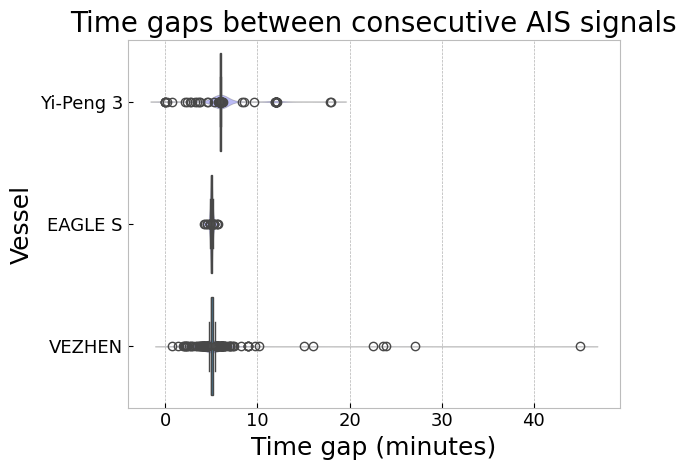

In [7]:
gaps_yipeng3 = yipeng3_df['static_timestamp'].diff(1) / timedelta(minutes=1)
gaps_vezhen = vezhen_df['DATE TIME (UTC)'].diff(1) / timedelta(minutes=1)
gaps_eagles = eagle_s_df['DATE TIME (UTC)'].diff(1) / timedelta(minutes=1)

gaps_df = pd.DataFrame({
    "Vessel": ['Yi-Peng 3'] * gaps_yipeng3.shape[0] + ['EAGLE S'] * gaps_eagles.shape[0] + ['VEZHEN'] * gaps_vezhen.shape[0],
    "Time gap": gaps_yipeng3.to_list() + gaps_eagles.to_list() + gaps_vezhen.to_list()
})

sns.boxplot(
    data=gaps_df,
    y='Vessel',
    x='Time gap'
)
sns.violinplot(
    data=gaps_df,
    y='Vessel',
    x='Time gap',
    color='blue',
    alpha=0.3
)

plt.title('Time gaps between consecutive AIS signals', size=20)
plt.tick_params(axis='both', labelsize=13)
plt.xlabel('Time gap (minutes)', size=18)
plt.ylabel('Vessel', size=18)

plt.tight_layout()
plt.savefig('../images/Figure_1.png', dpi=750)
plt.show()

In [8]:
gaps_yipeng3.mean()

6.428645833333333

In [9]:
gaps_eagles.mean()

5.011666666666667

In [10]:
gaps_vezhen.mean()

5.4329311885612155

## Data preparation for ships

In [11]:
yipeng3_even_df = yipeng3_df\
    .set_index( 'static_timestamp')\
    .resample('300s')\
    .first()\
    .dropna(subset=['mmsi'])\
    .reset_index()

eagles_even_df = eagle_s_df\
    .set_index( 'DATE TIME (UTC)')\
    .resample('300s')\
    .first()\
    .dropna(subset=['MMSI'])\
    .reset_index()

vezhen_even_df = vezhen_df\
    .set_index( 'DATE TIME (UTC)')\
    .resample('300s')\
    .first()\
    .dropna(subset=['MMSI'])\
    .reset_index()

In [12]:
vezhen_even_df['DATE TIME (UTC)']

0     2025-01-25 00:00:00
1     2025-01-25 00:05:00
2     2025-01-25 00:10:00
3     2025-01-25 00:15:00
4     2025-01-25 00:20:00
              ...        
360   2025-01-26 09:25:00
361   2025-01-26 09:30:00
362   2025-01-26 09:35:00
363   2025-01-26 09:40:00
364   2025-01-26 09:45:00
Name: DATE TIME (UTC), Length: 365, dtype: datetime64[ns]

In [13]:
yipeng3_even_df['date_diff'] = yipeng3_even_df['static_timestamp'].diff(1) / timedelta(minutes=1)
eagles_even_df['date_diff'] = eagles_even_df['DATE TIME (UTC)'].diff(1) / timedelta(minutes=1)
vezhen_even_df['date_diff'] = vezhen_even_df['DATE TIME (UTC)'].diff(1) / timedelta(minutes=1)

yipeng3_even_df['dif'] = ( yipeng3_even_df['heading'] - yipeng3_even_df['course']  + 180) % 360 - 180
yipeng3_even_df['dif'] = yipeng3_even_df['dif'] / yipeng3_even_df['date_diff']

eagles_even_df['dif'] = ( eagles_even_df['HEADING'] - eagles_even_df['COURSE']  + 180) % 360 - 180
eagles_even_df['dif'] = eagles_even_df['dif'] / eagles_even_df['date_diff']

vezhen_even_df['dif'] = ( vezhen_even_df['HEADING'] - vezhen_even_df['COURSE']  + 180) % 360 - 180
vezhen_even_df['dif'] = vezhen_even_df['dif'] / vezhen_even_df['date_diff']

yipeng3_even_df['cog_delta'] = ( yipeng3_even_df['course'].diff(1) + 180) % 360 - 180
yipeng3_even_df['cog_delta'] = yipeng3_even_df['cog_delta'] / yipeng3_even_df['date_diff']

eagles_even_df['cog_delta'] = ( eagles_even_df['COURSE'].diff(1) + 180) % 360 - 180
eagles_even_df['cog_delta'] = eagles_even_df['cog_delta'] / eagles_even_df['date_diff']

vezhen_even_df['cog_delta'] = ( vezhen_even_df['COURSE'].diff(1) + 180) % 360 - 180
vezhen_even_df['cog_delta'] = vezhen_even_df['cog_delta'] / vezhen_even_df['date_diff']

### Normalize

In [14]:
vezhen_even_df['dif'] = vezhen_even_df['dif'] / 180 * 5
eagles_even_df['dif'] = eagles_even_df['dif'] / 180 * 5
yipeng3_even_df['dif'] = yipeng3_even_df['dif'] / 180 * 5

vezhen_even_df['delta_dif'] = vezhen_even_df['dif'].diff(1) / 2
eagles_even_df['delta_dif'] = eagles_even_df['dif'].diff(1) / 2
yipeng3_even_df['delta_dif'] = yipeng3_even_df['dif'].diff(1) / 2

vezhen_even_df['cog_delta'] = vezhen_even_df['cog_delta'] / 180 * 5
eagles_even_df['cog_delta'] = eagles_even_df['cog_delta'] / 180 * 5
yipeng3_even_df['cog_delta'] = yipeng3_even_df['cog_delta'] / 180 * 5

### Filter out incorrect data

In [15]:
eagles_even_df = eagles_even_df[eagles_even_df['SPEED'] <= 25.0]
vezhen_even_df = vezhen_even_df[vezhen_even_df['SPEED'] <= 25.0]
yipeng3_even_df = yipeng3_even_df[yipeng3_even_df['speed'] <= 25.0]

### Calculate the moving mean to smooth

In [16]:
for df in [yipeng3_even_df, eagles_even_df, vezhen_even_df]:
    for col in ['cog_delta', 'dif', 'delta_dif']:
        df[col] = np.cbrt(df[col]).rolling(3).mean()

[]

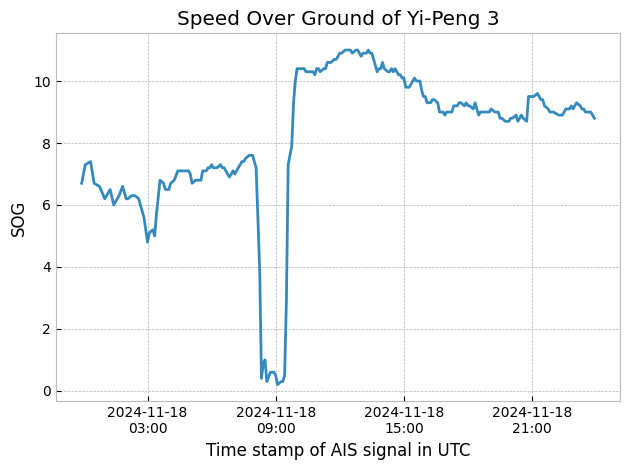

In [17]:
sns.lineplot(
    yipeng3_even_df,
    y='speed',
    x='static_timestamp'
)

yipeng3_ticks = [
    datetime(2024, 11, 18, 3) + timedelta(hours=i)
    for i in range(0, 24, 6)
]
yipeng3_labels = [
    tick.strftime('%Y-%m-%d\n%H:%S')
    for tick in yipeng3_ticks
]

plt.xticks(
    ticks=yipeng3_ticks,
    labels=yipeng3_labels
)

plt.xlabel('Time stamp of AIS signal in UTC')
plt.ylabel('SOG')
plt.title('Speed Over Ground of Yi-Peng 3')

plt.tight_layout()
plt.savefig('../images/speed-over-ground-yipeng3.png', dpi=750)

plt.plot()

[]

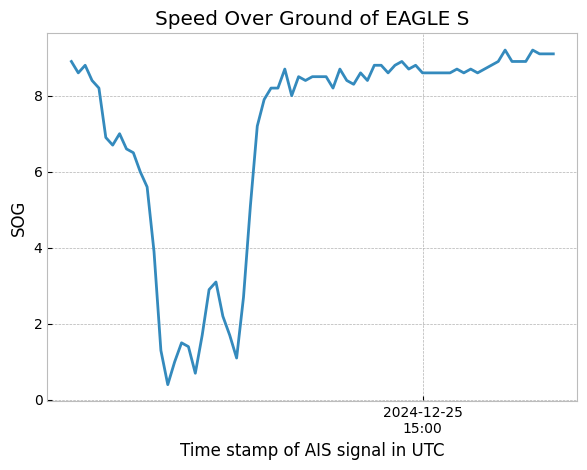

In [18]:
sns.lineplot(
    eagles_even_df,
    y='SPEED',
    x='DATE TIME (UTC)'
)

eagle_ticks = [
    datetime(2024, 12, 25, 3, 0) + timedelta(hours=i)
    for i in range(0, 51, 12)
]
eagle_labels = [
    tick.strftime('%Y-%m-%d\n%H:%S')
    for tick in eagle_ticks
]

plt.xticks(
    ticks=eagle_ticks,
    labels=eagle_labels
)


plt.xlabel('Time stamp of AIS signal in UTC')
plt.ylabel('SOG')
plt.title('Speed Over Ground of EAGLE S')

plt.tight_layout()
plt.savefig('../images/speed-over-ground-eagles.png', dpi=750)

plt.plot()

[]

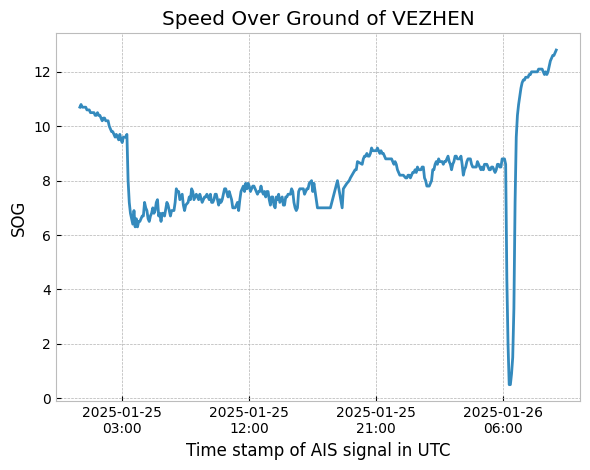

In [19]:
sns.lineplot(
    vezhen_even_df,
    y='SPEED',
    x='DATE TIME (UTC)'
)
vezhen_ticks = [
    datetime(2025, 1, 25, 3, 0) + timedelta(hours=i)
    for i in range(0, 49, 9)
]
vezhen_labels = [
    tick.strftime('%Y-%m-%d\n%H:%S')
    for tick in vezhen_ticks
]

plt.xticks(
    ticks=vezhen_ticks,
    labels=vezhen_labels
)


plt.xlabel('Time stamp of AIS signal in UTC')
plt.ylabel('SOG')
plt.title('Speed Over Ground of VEZHEN')

plt.tight_layout()
plt.savefig('../images/speed-over-ground-vezhen.png', dpi=750)

plt.plot()

[]

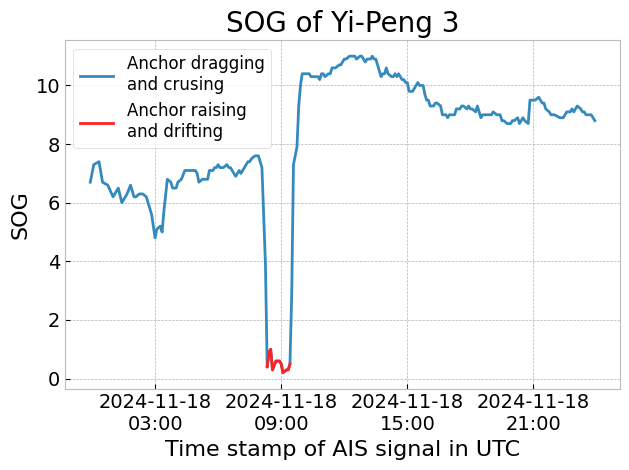

In [20]:
plt.plot(
    yipeng3_even_df['static_timestamp'],
    yipeng3_even_df['speed'],
    label='Anchor dragging\nand crusing'
)

yipeng3_anchor_raising = yipeng3_even_df[
    (yipeng3_even_df['static_timestamp'].dt.to_pydatetime() >= datetime(2024, 11, 18, 8, 20, tzinfo=timezone.utc)) &
    (yipeng3_even_df['static_timestamp'].dt.to_pydatetime() < datetime(2024, 11, 18, 9, 30, tzinfo=timezone.utc))
]

plt.plot(
    yipeng3_anchor_raising['static_timestamp'],
    yipeng3_anchor_raising['speed'],
    color='#ff2222',
    label='Anchor raising\nand drifting'
)

yipeng3_ticks = [
    datetime(2024, 11, 18, 3) + timedelta(hours=i)
    for i in range(0, 24, 6)
]
yipeng3_labels = [
    tick.strftime('%Y-%m-%d\n%H:%S')
    for tick in yipeng3_ticks
]

plt.xticks(
    ticks=yipeng3_ticks,
    labels=yipeng3_labels
)

plt.xlabel('Time stamp of AIS signal in UTC', size=16)
plt.ylabel('SOG', size=16)
plt.title('SOG of Yi-Peng 3', size=20)

plt.tick_params(axis='y', labelsize=14)
plt.tick_params(axis='x', labelsize=14)
plt.legend(fontsize=12)

plt.tight_layout()
plt.savefig('../images/Figure_3.png', dpi=750)

plt.plot()

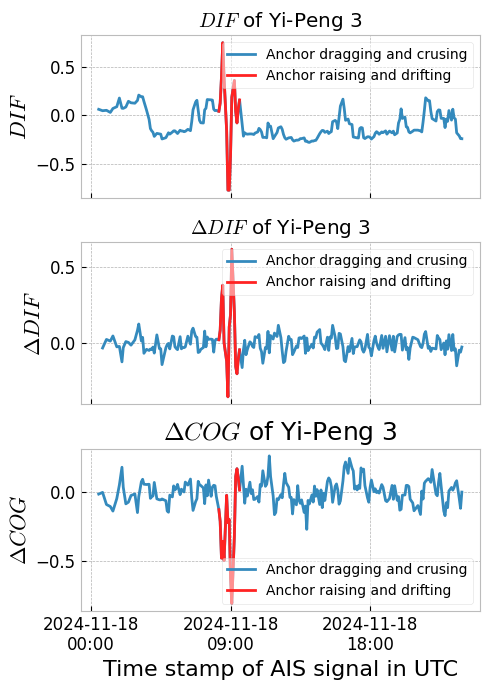

In [21]:
fig, axs = plt.subplots(nrows=3, figsize=(5, 7), sharex=True)

axs[0].plot(
    yipeng3_even_df['static_timestamp'],
    yipeng3_even_df['dif'],
    label='Anchor dragging and crusing'
)

yipeng3_anchor_raising = yipeng3_even_df[
    (yipeng3_even_df['static_timestamp'].dt.to_pydatetime() >= datetime(2024, 11, 18, 8, 10, tzinfo=timezone.utc)) &
    (yipeng3_even_df['static_timestamp'].dt.to_pydatetime() < datetime(2024, 11, 18, 9, 40, tzinfo=timezone.utc))
]

axs[0].plot(
    yipeng3_anchor_raising['static_timestamp'],
    yipeng3_anchor_raising['dif'],
    color='#ff2222',
    label='Anchor raising and drifting'
)

yipeng3_ticks = [
    datetime(2024, 11, 18, 0) + timedelta(hours=i)
    for i in range(0, 24, 9)
]
yipeng3_labels = [
    tick.strftime('%Y-%m-%d\n%H:%S')
    for tick in yipeng3_ticks
]

axs[0].set_xticks(
    ticks=yipeng3_ticks,
    labels=yipeng3_labels
)

axs[0].set_ylabel('$DIF$', size=16)
axs[0].set_title('$DIF$ of Yi-Peng 3')
axs[0].legend(loc="upper right", fontsize=10, framealpha=0.5)

axs[1].plot(
    yipeng3_even_df['static_timestamp'],
    yipeng3_even_df['delta_dif'],
    label='Anchor dragging and crusing'
)

yipeng3_anchor_raising = yipeng3_even_df[
    (yipeng3_even_df['static_timestamp'].dt.to_pydatetime() >= datetime(2024, 11, 18, 8, 10, tzinfo=timezone.utc)) &
    (yipeng3_even_df['static_timestamp'].dt.to_pydatetime() < datetime(2024, 11, 18, 9, 40, tzinfo=timezone.utc))
]

axs[1].plot(
    yipeng3_anchor_raising['static_timestamp'],
    yipeng3_anchor_raising['delta_dif'],
    color='#ff2222',
    label='Anchor raising and drifting'
)

axs[1].set_xticks(
    ticks=yipeng3_ticks,
    labels=yipeng3_labels
)

axs[1].set_ylabel('$\Delta DIF$', size=16)
axs[1].set_title('$\Delta DIF$ of Yi-Peng 3')
axs[1].legend(loc="upper right", fontsize=10, framealpha=0.5)

axs[2].plot(
    yipeng3_even_df['static_timestamp'],
    yipeng3_even_df['cog_delta'],
    label='Anchor dragging and crusing'
)

yipeng3_anchor_raising = yipeng3_even_df[
    (yipeng3_even_df['static_timestamp'].dt.to_pydatetime() >= datetime(2024, 11, 18, 8, 10, tzinfo=timezone.utc)) &
    (yipeng3_even_df['static_timestamp'].dt.to_pydatetime() < datetime(2024, 11, 18, 9, 40, tzinfo=timezone.utc))
]

axs[2].plot(
    yipeng3_anchor_raising['static_timestamp'],
    yipeng3_anchor_raising['cog_delta'],
    color='#ff2222',
    label='Anchor raising and drifting'
)

axs[2].set_xticks(
    ticks=yipeng3_ticks,
    labels=yipeng3_labels
)

axs[2].set_xlabel('Time stamp of AIS signal in UTC', size=16)
axs[2].set_ylabel('$\Delta COG$', size=16)
axs[2].set_title('$\Delta COG$ of Yi-Peng 3', size=18)
axs[2].legend(loc='lower right', fontsize=10, framealpha=0.5)

for ax in axs:
    ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('../images/features_yipeng3.png', dpi=750)

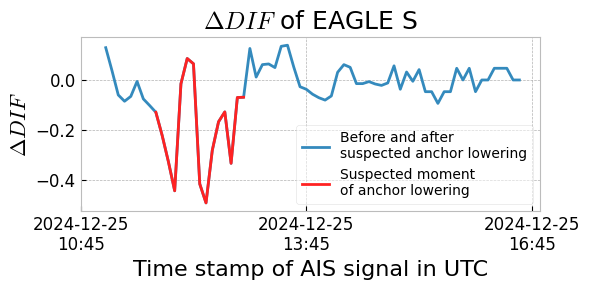

In [22]:
fig, ax = plt.subplots(figsize=(6,3))

eagles_even_df_pre = eagles_even_df[
    eagles_even_df['DATE TIME (UTC)'] < datetime(2024, 12, 25, 16, 40)
]
eagles_even_df_raise = eagles_even_df[
    (eagles_even_df['DATE TIME (UTC)'] < datetime(2024, 12, 25, 13, 0)) &
    (eagles_even_df['DATE TIME (UTC)'] > datetime(2024, 12, 25, 11, 40))
]

eagles_ticks = [
    datetime(2024, 12, 25, 10, 45) + timedelta(hours=i)
    for i in range(0, 7, 3)
]
eagles_labels = [
    tick.strftime('%Y-%m-%d\n%H:%M')
    for tick in eagles_ticks
]

ax.plot(
    eagles_even_df_pre['DATE TIME (UTC)'],
    eagles_even_df_pre['delta_dif'],
    label='Before and after\nsuspected anchor lowering'
)
ax.plot(
    eagles_even_df_raise['DATE TIME (UTC)'],
    eagles_even_df_raise['delta_dif'],
    color='#ff2222',
    label='Suspected moment\nof anchor lowering'
)

ax.set_xticks(
    ticks=eagles_ticks,
    labels=eagles_labels
)

ax.set_xlabel('Time stamp of AIS signal in UTC', size=16)
ax.set_ylabel('$\Delta DIF$', size=16)
ax.set_title('$\Delta DIF$ of EAGLE S', size=18)

ax.legend(loc='lower right', fontsize=10, framealpha=0.5)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('../images/delta-dif-eagles.png', dpi=750)

In [23]:
low_speed_mask = eagles_even_df['SPEED'] < 2

timestamps_low_speed_min = eagles_even_df.loc[low_speed_mask, 'DATE TIME (UTC)'].min()
timestamps_low_speed_max = eagles_even_df.loc[low_speed_mask, 'DATE TIME (UTC)'].max()

low_speed_mask = (
    (eagles_even_df['DATE TIME (UTC)'] <= timestamps_low_speed_max) &
    (eagles_even_df['DATE TIME (UTC)'] >= timestamps_low_speed_min)
)

timestamps_low_speed = eagles_even_df[low_speed_mask]['DATE TIME (UTC)']

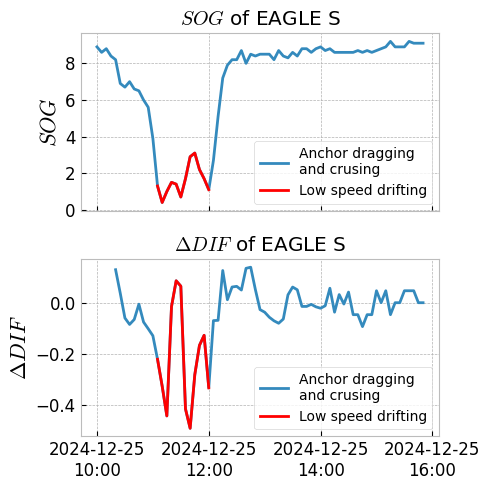

In [24]:
fig, axs = plt.subplots(nrows=2, figsize=(5, 5), sharex=True)
lower_bound = datetime(2024, 12, 25, 10, 45)
upper_bound = datetime(2024, 12, 25, 16, 35)

axs[0].plot(
    eagles_even_df['DATE TIME (UTC)'],
    eagles_even_df['SPEED'],
    label='Anchor dragging\nand crusing'
)
axs[0].plot(
    timestamps_low_speed,
    eagles_even_df[low_speed_mask]['SPEED'],
    label='Low speed drifting',
    color='red'
)
eagles_ticks = [
    datetime(2024, 12, 25, 10, 45) + timedelta(hours=i)
    for i in range(0, 8, 2)
]
eagles_labels = [
    tick.strftime('%Y-%m-%d\n%H:%S')
    for tick in eagles_ticks
]

axs[0].set_xticks(
    ticks=eagles_ticks,
    labels=eagles_labels
)

axs[0].set_ylabel('$SOG$', size=16)
axs[0].set_title('$SOG$ of EAGLE S')
axs[0].legend(loc="lower right", fontsize=10)

axs[1].plot(
    eagles_even_df['DATE TIME (UTC)'],
    eagles_even_df['delta_dif'],
    label='Anchor dragging\nand crusing'
)
axs[1].plot(
    timestamps_low_speed,
    eagles_even_df[low_speed_mask]['delta_dif'],
    label='Low speed drifting',
    color='red'
)
axs[1].set_xticks(
    ticks=eagles_ticks,
    labels=eagles_labels
)

axs[1].set_ylabel('$\Delta DIF$', size=16)
axs[1].set_title('$\Delta DIF$ of EAGLE S')
axs[1].legend(loc="lower right", fontsize=10)

for ax in axs:
    ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('../images/deltacog-and-speed-eagle-s.png', dpi=750)

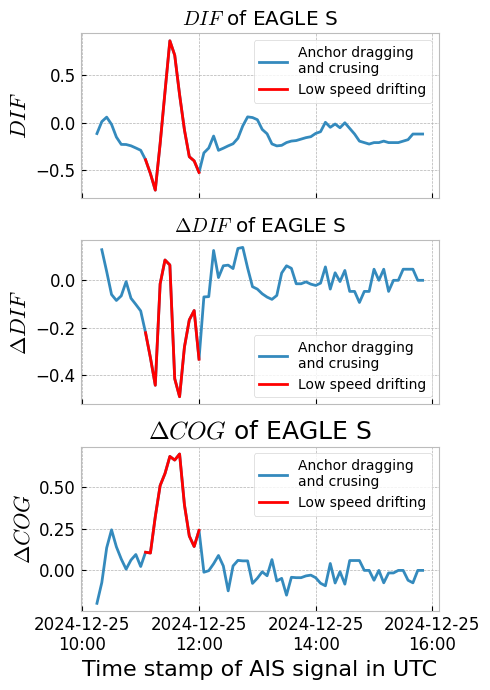

In [25]:
fig, axs = plt.subplots(nrows=3, figsize=(5, 7), sharex=True)
lower_bound = datetime(2024, 12, 25, 10, 45)
upper_bound = datetime(2024, 12, 25, 16, 35)

axs[0].plot(
    eagles_even_df['DATE TIME (UTC)'],
    eagles_even_df['dif'],
    label='Anchor dragging\nand crusing'
)
axs[0].plot(
    timestamps_low_speed,
    eagles_even_df[low_speed_mask]['dif'],
    label='Low speed drifting',
    color='red'
)
eagles_ticks = [
    datetime(2024, 12, 25, 10, 45) + timedelta(hours=i)
    for i in range(0, 8, 2)
]
eagles_labels = [
    tick.strftime('%Y-%m-%d\n%H:%S')
    for tick in eagles_ticks
]

axs[0].set_xticks(
    ticks=eagles_ticks,
    labels=eagles_labels
)

axs[0].set_ylabel('$DIF$', size=16)
axs[0].set_title('$DIF$ of EAGLE S')
axs[0].legend(loc="upper right", fontsize=10)

axs[1].plot(
    eagles_even_df['DATE TIME (UTC)'],
    eagles_even_df['delta_dif'],
    label='Anchor dragging\nand crusing'
)
axs[1].plot(
    timestamps_low_speed,
    eagles_even_df[low_speed_mask]['delta_dif'],
    label='Low speed drifting',
    color='red'
)
axs[1].set_xticks(
    ticks=eagles_ticks,
    labels=eagles_labels
)

axs[1].set_ylabel('$\Delta DIF$', size=16)
axs[1].set_title('$\Delta DIF$ of EAGLE S')
axs[1].legend(loc="lower right", fontsize=10)

axs[2].plot(
    eagles_even_df['DATE TIME (UTC)'],
    eagles_even_df['cog_delta'],
    label='Anchor dragging\nand crusing'
)
axs[2].plot(
    timestamps_low_speed,
    eagles_even_df[low_speed_mask]['cog_delta'],
    label='Low speed drifting',
    color='red'
)
axs[2].set_xticks(
    ticks=eagles_ticks,
    labels=eagles_labels
)

axs[2].set_xlabel('Time stamp of AIS signal in UTC', size=16)
axs[2].set_ylabel('$\Delta COG$', size=16)
axs[2].set_title('$\Delta COG$ of EAGLE S', size=18)
axs[2].legend(loc='upper right', fontsize=10)

for ax in axs:
    ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('../images/features-eagle-s.png', dpi=750)

In [26]:
vezhen_even_df['DATE TIME (UTC)'].max()

Timestamp('2025-01-26 09:45:00')

In [27]:
lower_bound = datetime(2025, 1, 25, 0, 0)
upper_bound = datetime(2025, 1, 26, 9, 45)

# look-up vezhen-storm-check.ipynb:
storm_start = 14
storm_end = 60

In [28]:
vezhen_even_df['DATE TIME (UTC)'].values[storm_start:storm_end],

(array(['2025-01-25T01:10:00.000000000', '2025-01-25T01:15:00.000000000',
        '2025-01-25T01:20:00.000000000', '2025-01-25T01:25:00.000000000',
        '2025-01-25T01:30:00.000000000', '2025-01-25T01:35:00.000000000',
        '2025-01-25T01:40:00.000000000', '2025-01-25T01:45:00.000000000',
        '2025-01-25T01:50:00.000000000', '2025-01-25T01:55:00.000000000',
        '2025-01-25T02:00:00.000000000', '2025-01-25T02:05:00.000000000',
        '2025-01-25T02:10:00.000000000', '2025-01-25T02:15:00.000000000',
        '2025-01-25T02:20:00.000000000', '2025-01-25T02:25:00.000000000',
        '2025-01-25T02:30:00.000000000', '2025-01-25T02:35:00.000000000',
        '2025-01-25T02:40:00.000000000', '2025-01-25T02:45:00.000000000',
        '2025-01-25T02:50:00.000000000', '2025-01-25T02:55:00.000000000',
        '2025-01-25T03:00:00.000000000', '2025-01-25T03:05:00.000000000',
        '2025-01-25T03:10:00.000000000', '2025-01-25T03:15:00.000000000',
        '2025-01-25T03:20:00.000000000

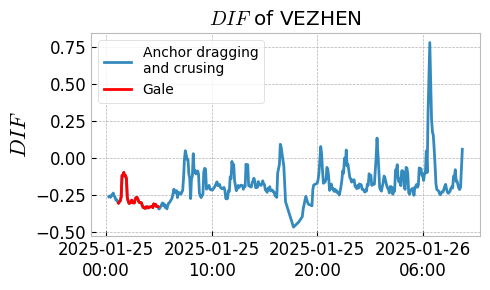

In [29]:
fig, ax = plt.subplots(nrows=1, figsize=(5, 3))
lower_bound = datetime(2025, 1, 25, 0, 0)
upper_bound = datetime(2025, 1, 26, 9, 45)

ax.plot(
    vezhen_even_df['DATE TIME (UTC)'],
    vezhen_even_df['dif'],
    label='Anchor dragging\nand crusing'
)
ax.plot(
    vezhen_even_df['DATE TIME (UTC)']\
        .values[storm_start:storm_end],
    vezhen_even_df['dif']\
        .values[storm_start:storm_end],
    label='Gale',
    color='red'
)
vezhen_ticks = [
    lower_bound + timedelta(hours=i)
    for i in range(0, 34, 10)
]
vezhen_labels = [
    tick.strftime('%Y-%m-%d\n%H:%S')
    for tick in vezhen_ticks
]

ax.set_xticks(
    ticks=vezhen_ticks,
    labels=vezhen_labels
)

ax.set_ylabel('$DIF$', size=16)
ax.set_title('$DIF$ of VEZHEN')
ax.legend(loc="upper left", fontsize=10)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('../images/dif-vezhen.png', dpi=750)

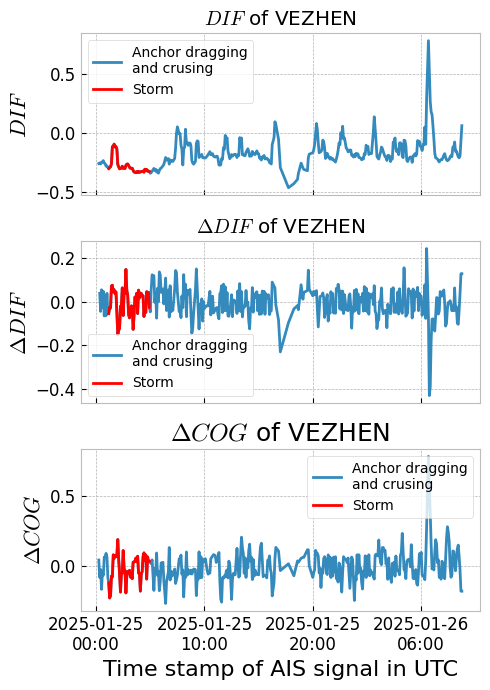

In [30]:
fig, axs = plt.subplots(nrows=3, figsize=(5, 7), sharex=True)
lower_bound = datetime(2025, 1, 25, 0, 0)
upper_bound = datetime(2025, 1, 26, 9, 45)

axs[0].plot(
    vezhen_even_df['DATE TIME (UTC)'],
    vezhen_even_df['dif'],
    label='Anchor dragging\nand crusing'
)
axs[0].plot(
    vezhen_even_df['DATE TIME (UTC)']\
        .values[storm_start:storm_end],
    vezhen_even_df['dif']\
        .values[storm_start:storm_end],
    label='Storm',
    color='red'
)
vezhen_ticks = [
    lower_bound + timedelta(hours=i)
    for i in range(0, 34, 10)
]
vezhen_labels = [
    tick.strftime('%Y-%m-%d\n%H:%S')
    for tick in vezhen_ticks
]

axs[0].set_xticks(
    ticks=vezhen_ticks,
    labels=vezhen_labels
)

axs[0].set_ylabel('$DIF$', size=16)
axs[0].set_title('$DIF$ of VEZHEN')
axs[0].legend(loc="upper left", fontsize=10)

axs[1].plot(
    vezhen_even_df['DATE TIME (UTC)'],
    vezhen_even_df['delta_dif'],
    label='Anchor dragging\nand crusing'
)
axs[1].plot(
    vezhen_even_df['DATE TIME (UTC)']\
        .values[storm_start:storm_end],
    vezhen_even_df['delta_dif']\
        .values[storm_start:storm_end],
    label='Storm',
    color='red'
)
axs[1].set_xticks(
    ticks=vezhen_ticks,
    labels=vezhen_labels
)

axs[1].set_ylabel('$\Delta DIF$', size=16)
axs[1].set_title('$\Delta DIF$ of VEZHEN')
axs[1].legend(loc="lower left", fontsize=10)

axs[2].plot(
    vezhen_even_df['DATE TIME (UTC)'],
    vezhen_even_df['cog_delta'],
    label='Anchor dragging\nand crusing'
)
axs[2].plot(
    vezhen_even_df['DATE TIME (UTC)']\
        .values[storm_start:storm_end],
    vezhen_even_df['cog_delta']\
        .values[storm_start:storm_end],
    label='Storm',
    color='red'
)
axs[2].set_xticks(
    ticks=vezhen_ticks,
    labels=vezhen_labels
)

axs[2].set_xlabel('Time stamp of AIS signal in UTC', size=16)
axs[2].set_ylabel('$\Delta COG$', size=16)
axs[2].set_title('$\Delta COG$ of VEZHEN', size=18)
axs[2].legend(loc='upper right', fontsize=10)

for ax in axs:
    ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig('../images/features-vezhen.png', dpi=750)

## Trajectories

- Both trajectories follow regular tracks overall.
- Eagle S trajectory becomes highly anomalous in the end - it does two loops.
- Vezhen trajectory is completely normal throughout the whole voyage. It is important to note that there was a turn towards a port.

In [33]:
m = folium.Map(location=[55.5, 15.5], zoom_start=8, tiles="OpenTopoMap")

for (mmsi, day), df_mmsi in all_vessel_near_yipeng.groupby(['MMSI', 'day']):
    coord_list = df_mmsi.apply(
        lambda row: [ row['Latitude'], row['Longitude'] ],
        axis='columns'
    )\
        .tolist()

    if len(coord_list) < 10:
        continue

    folium.PolyLine(
        coord_list,
        opacity=0.15,
        weight=1
    ).add_to(m)

# Source - https://stackoverflow.com/a/61046406
# Posted by sentence
# Retrieved 2026-09-21, License - CC BY-SA 4.0
folium.Polygon([
    [54, 12.5],
    [57, 12.5],
    [57, 18.5],
    [54, 18.5],
    [54, 12.5],
], color='black', dash_array='10').add_to(m)

folium.Polygon([
    [54.5, 13.0],
    [56.5, 13.0],
    [56.5, 18.0],
    [54.5, 18.0],
    [54.5, 13.0],
], color='black').add_to(m)

In [ ]:
coord_list_yipeng = yipeng3_even_df.apply(
    lambda row: [ row['latitude'], row['longitude'] ],
    axis='columns'
).tolist()

folium.PolyLine(
    coord_list_yipeng,
    weight=8,
    color='red'
).add_to(m)
m

In [60]:
!!pip install selenium

['Requirement already satisfied: selenium in /home/lukas/straipsnis/venv/lib/python3.8/site-packages (4.27.1)',
 'Requirement already satisfied: websocket-client~=1.8 in /home/lukas/straipsnis/venv/lib/python3.8/site-packages (from selenium) (1.8.0)',
 'Requirement already satisfied: trio-websocket~=0.9 in /home/lukas/straipsnis/venv/lib/python3.8/site-packages (from selenium) (0.12.2)',
 'Requirement already satisfied: urllib3[socks]<3,>=1.26 in /home/lukas/straipsnis/venv/lib/python3.8/site-packages (from selenium) (2.2.3)',
 'Requirement already satisfied: certifi>=2021.10.8 in /home/lukas/straipsnis/venv/lib/python3.8/site-packages (from selenium) (2026.5.20)',
 'Requirement already satisfied: trio~=0.17 in /home/lukas/straipsnis/venv/lib/python3.8/site-packages (from selenium) (0.27.0)',
 'Requirement already satisfied: typing_extensions~=4.9 in /home/lukas/straipsnis/venv/lib/python3.8/site-packages (from selenium) (4.13.2)',
 'Requirement already satisfied: wsproto>=0.14 in /hom

In [35]:
# Source - https://stackoverflow.com/a/62440518
# Posted by Michel Metran
# Retrieved 2026-09-21, License - CC BY-SA 4.0

import io
from PIL import Image

img_data = m._to_png(30)
img = Image.open(io.BytesIO(img_data))
img.save('yipeng3-map-ieee.png')

In [62]:
all_vessel_df['DAY'] = pd.to_datetime(all_vessel_df['DATE TIME (UTC)']).dt.date

In [73]:
m = folium.Map(location=[58.75, 22], zoom_start=7, tiles="OpenTopoMap")

for (mmsi, day), df_mmsi in all_vessel_df.groupby(['MMSI', 'DAY']):
    coord_list = df_mmsi.apply(
        lambda row: [ row['LATITUDE'], row['LONGITUDE'] ],
        axis='columns'
    )\
        .tolist()

    if len(coord_list) < 10:
        continue

    folium.PolyLine(
        coord_list,
        opacity=0.35,
        weight=1,
        color='#008080'
    ).add_to(m)


# Source - https://stackoverflow.com/a/61046406
# Posted by sentence
# Retrieved 2026-09-21, License - CC BY-SA 4.0
folium.Polygon([
    [56.5, 18],
    [61, 18],
    [61, 26.0],
    [56.5, 26.0],
    [56.5, 18],
], color='black', dash_array='10').add_to(m)

folium.Polygon([
    [57, 18.5],
    [60.5, 18.5],
    [60.5, 25.5],
    [57, 25.5],
    [57, 18.5],
], color='black').add_to(m)


In [ ]:
coord_list_eagles = eagles_even_df.apply(
    lambda row: [ row['LATITUDE'], row['LONGITUDE'] ],
    axis='columns'
).tolist()

folium.PolyLine(
    coord_list_eagles,
    weight=10,
    color='red'
).add_to(m)

coord_list_vezhen = vezhen_even_df[
    (vezhen_even_df['DATE TIME (UTC)'] < datetime(2025, 1, 25, 20)) &
    (vezhen_even_df['DATE TIME (UTC)'] > datetime(2025, 1, 25, 6))
].apply(
    lambda row: [ row['LATITUDE'], row['LONGITUDE'] ],
    axis='columns'
).tolist()

folium.PolyLine(
    coord_list_vezhen,
    weight=10,
    color='purple'
).add_to(m)
m

In [66]:
# Source - https://stackoverflow.com/a/62440518
# Posted by Michel Metran
# Retrieved 2026-09-21, License - CC BY-SA 4.0

import io
from PIL import Image

img_data = m._to_png(30)
img = Image.open(io.BytesIO(img_data))
img.save('eagles-vezhen-map.png')